In [1]:
# !pip install seaborn
# !pip install wordcloud

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)


import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))


/kaggle/input/amazon-reviews-2018-full-dataset/amazon_reviews.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("/kaggle/input/amazon-reviews-2018-full-dataset/amazon_reviews.csv")

In [3]:
# data.describe()
data.head()
data = data.sample(frac=0.2, random_state=42)




# **All Category Count**
**above plot shows all the category count present in the dataset.**

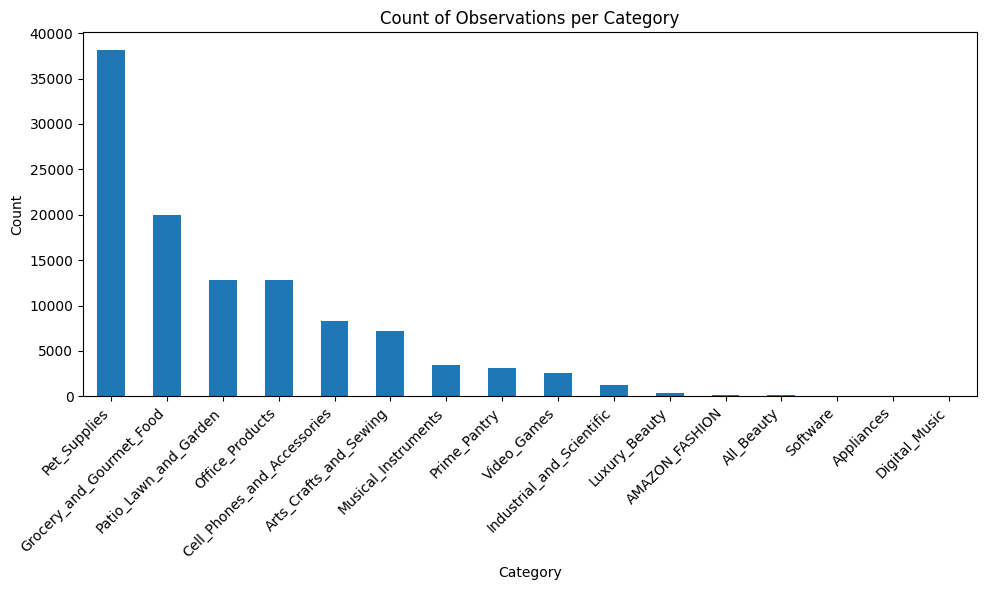

In [4]:

category_counts = data['category'].value_counts()
category_counts
plt.figure(figsize=(10, 6))
category_counts.plot(kind='bar')
plt.xlabel('Category')
plt.ylabel('Count')
plt.title('Count of Observations per Category')
plt.xticks(rotation=45, ha='right')  # Rotate x-axis labels for better readability
plt.tight_layout()  # Adjust layout to prevent clipping of labels
plt.show()

# **Plotting All Categories vs rating graph**
**This plot shows the rating count of each category available in the dataset**

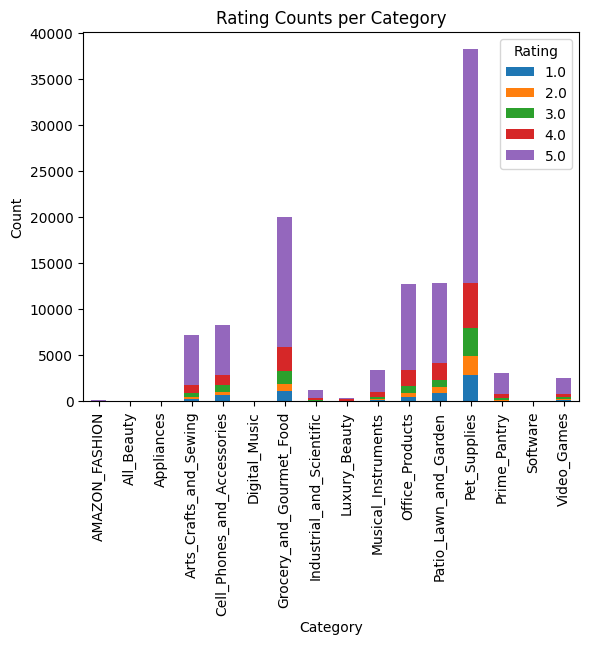

In [5]:
rating_counts_per_category = data.groupby('category')['rating'].value_counts().unstack(fill_value=0)
rating_counts_per_category


# Plot stacked bar chart
rating_counts_per_category.plot(kind='bar', stacked=True)
plt.xlabel('Category')
plt.ylabel('Count')
plt.title('Rating Counts per Category')
plt.legend(title='Rating')
plt.show()

In [6]:
category_counts = data['category'].value_counts()

# Get top 8 categories
top_5_categories = category_counts.head(5)

top_5_categories_list = top_5_categories.index.tolist()
top_5_categories_list


['Pet_Supplies',
 'Grocery_and_Gourmet_Food',
 'Patio_Lawn_and_Garden',
 'Office_Products',
 'Cell_Phones_and_Accessories']

/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

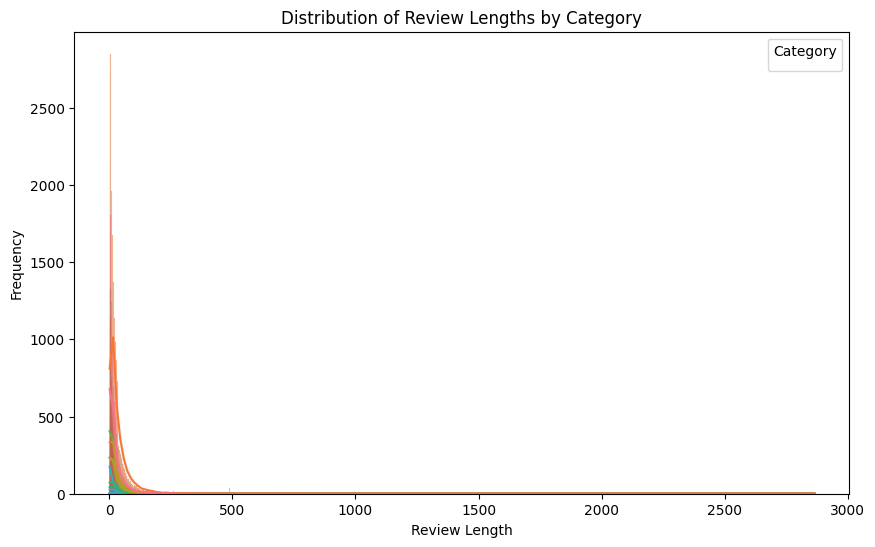

In [7]:
# Calculate length of reviews (in words) excluding missing values
data['review_length'] = data['reviewText'].dropna().apply(lambda x: len(x.split()))

# Plot distribution of review lengths
plt.figure(figsize=(10, 6))
sns.histplot(data=data, x='review_length', hue='category', kde=True)
plt.xlabel('Review Length')
plt.ylabel('Frequency')
plt.title('Distribution of Review Lengths by Category')
plt.legend(title='Category')
plt.show()


# Showing WordCount per category
**this Plot shows the frequency of words in form of a WordCloud..**

**showing top 200 words only.. for top 5 category as per review counts..**

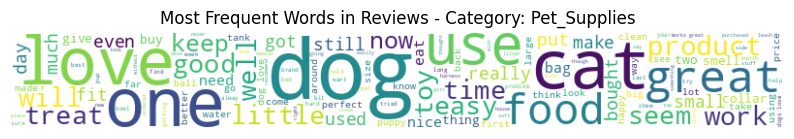

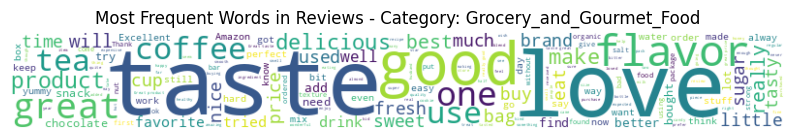

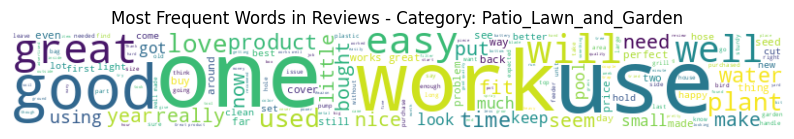

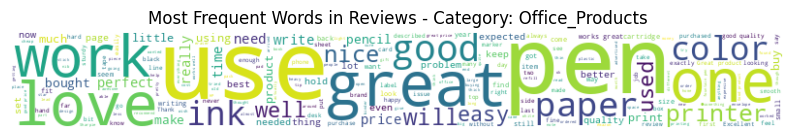

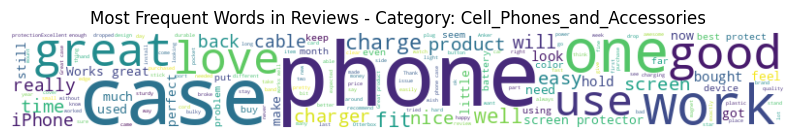

In [8]:
from wordcloud import WordCloud

# Generate word cloud for each category
for category in top_5_categories_list:
    # Drop rows with missing values in 'reviewText' column
    text = ' '.join(data[data['category'] == category]['reviewText'].dropna().astype(str))
    
    # Create WordCloud object with max_words parameter
    wordcloud = WordCloud(width=800, height=100, background_color='white', max_words=200).generate(text)
    
    plt.figure(figsize=(10, 6))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.title(f'Most Frequent Words in Reviews - Category: {category}')
    plt.axis('off')
    plt.show()


/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
/opt/conda/lib/python3.10/site-packages/seaborn/_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-l

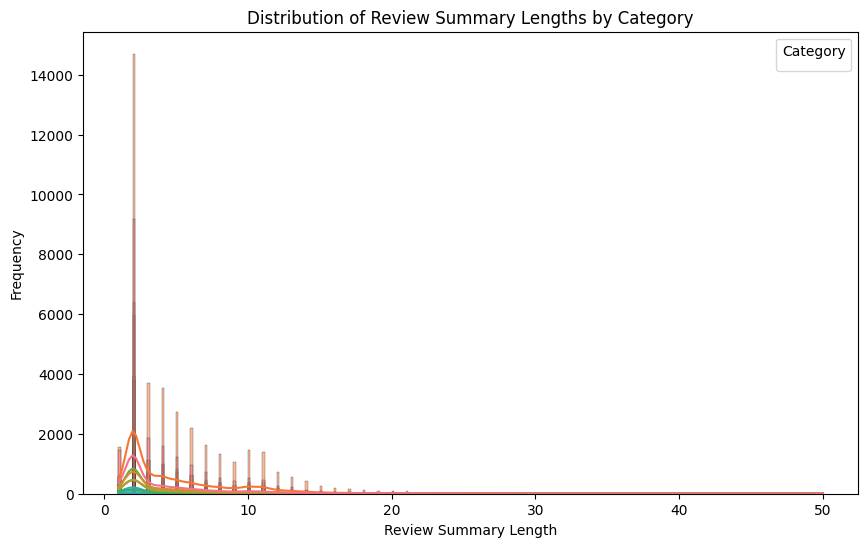

In [9]:
# Calculate length of review summaries (in words or characters)
data['summary_length'] = data['summary'].dropna().apply(lambda x: len(x.split()))  # Number of words
# data['summary_length'] = data['summary'].apply(len)  # Number of characters

# Plot distribution of review summary lengths
plt.figure(figsize=(10, 6))
sns.histplot(data=data, x='summary_length', hue='category', kde=True)
plt.xlabel('Review Summary Length')
plt.ylabel('Frequency')
plt.title('Distribution of Review Summary Lengths by Category')
plt.legend(title='Category')
plt.show()

# Making shallow learning models..
1. making logistic regression model

In [10]:
import pandas as pd

# Assuming 'data' is the original DataFrame and 'category' is the column containing category information

# Step 1: Filter the dataset to include only instances from the top 5 categories
top_5_categories = data['category'].value_counts().head(5).index.tolist()
filtered_data = data[data['category'].isin(top_5_categories)]

# Step 2: Determine the class with the minimum number of instances among the top 5 categories
min_class_size = filtered_data['category'].value_counts().min()

# Step 3: Sample instances from each category to match the size of the smallest class
sampled_data = pd.DataFrame()
for category in top_5_categories:
    category_data = filtered_data[filtered_data['category'] == category]
    sampled_category_data = category_data.sample(min_class_size, replace=True, random_state=42)  # Sampling with replacement
    sampled_data = pd.concat([sampled_data, sampled_category_data])

# Step 4: Combine the sampled instances from each category to create the new DataFrame
new_df = sampled_data.reset_index(drop=True)

# Display the new DataFrame
new_df.head()


,userName,verified,itemName,description,image,brand,feature,category,price,rating,reviewTime,summary,reviewText,vote,review_length,summary_length
0,Judilyn,True,"simplehuman Large Pet Food Storage Can, Brushe...","['<div class=""aplus"" >', ""Store your dog or ca...",['https://images-na.ssl-images-amazon.com/imag...,simplehuman,"['Airtight seal keeps food fresh', 'Magnetic l...",Pet_Supplies,$119.99,5.0,2018-05-24,"High quality, worth the price",Using it for cat litter. Fit two 42 lb bags wi...,0,41.0,5.0
1,Heather,True,JW Pet Company 46137 EverTuff Treat Pod Nylon ...,['Ever tuff Nylon Treat Pods are on a durable ...,['https://images-na.ssl-images-amazon.com/imag...,Petmate,['Ever tuff Nylon Treat Pods are on a durable ...,Pet_Supplies,$7.34,5.0,2018-04-17,This is a great toy for our puppy,This is a great toy for our puppy. It holds sn...,0,25.0,8.0
2,Amazon Customer,True,"Nylabone Flavor Frenzy Power Chew Triple Pack,...","['Nylabone Frenzy Petite Triple Pack Pancakes,...",['https://images-na.ssl-images-amazon.com/imag...,Nylabone,"['Long-lasting chew toy', 'Fun flavors', 'Disc...",Pet_Supplies,$4.65,4.0,2018-04-04,Four Stars,A lot smaller than I thought they were going t...,0,17.0,2.0
3,Bryan,True,Shirakura Shrimp Food --- Herbal Product Incre...,[],['https://images-na.ssl-images-amazon.com/imag...,SunGrow,"[""EXCRUCIATING TASTY HERBAL FOOD FOR SHRIMPS -...",Pet_Supplies,$12.95,3.0,2018-02-13,... it once in awhile but don't really seem to...,Shrimp pick at it once in awhile but don't rea...,0,22.0,20.0
4,Robert,True,New All Natural Anti Itch Oatmeal Dog Shampoo ...,"[""Our great smelling all natural plant based p...",['https://images-na.ssl-images-amazon.com/imag...,Bodhi Dog,"['SOOTHES AND MOISTURIZES DRY, ITCHY SKIN: Our...",Pet_Supplies,$14.99,5.0,2018-02-01,Five Stars,Will buy this again.,0,4.0,2.0


**Logistic Regression **

In [11]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline



new_df = new_df.dropna(subset=['reviewText', 'rating'])
X = new_df['reviewText']
y = new_df['rating']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer()

# get luxary Beauty category data for testing..
luxury_beauty_reviews = data[data['category'] == 'Luxury_Beauty']['reviewText']
luxury_beauty_reviews_rating = data[data['category'] == 'Luxury_Beauty']['rating']

# Fit and transform on training data
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

X_test_tfidf = tfidf_vectorizer.transform(X_test)

luxury_beauty_reviews_vectoriser =tfidf_vectorizer.transform(luxury_beauty_reviews)

print(" tokenizing finished..!!")

 tokenizing finished..!!


In [12]:

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Assuming 'new_df' is the preprocessed DataFrame containing review_text and rating columns


# Define the pipeline
model = Pipeline(steps=[('classifier', LogisticRegression())  # Logistic Regression classifier
])

# Train the model
model.fit(X_train_tfidf, y_train)

# Predictions
y_test_pred = model.predict(luxury_beauty_reviews_vectoriser)
y_train_pred = model.predict(X_train_tfidf)

# Evaluate the model
accuracy = accuracy_score(luxury_beauty_reviews_rating, y_test_pred)
print("Accuracy:", accuracy)


Accuracy: 0.746266859344894


/opt/conda/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


**Insight**
*the trained Logistic Regression model demonstrates strong performance in predicting rating categories based on review text features. With balanced precision and recall, as well as high accuracy on both training and test data, the model generalizes well to unseen instances. While achieving an accuracy of approximately 75% on the test data, the model exhibits a precision of around 70% and a recall of approximately 75%. These metrics indicate the model's ability to minimize false positives and negatives while effectively capturing true positives. However, there is still room for improvement, particularly in precision, suggesting potential avenues for further optimization such as hyperparameter tuning and feature engineering. Nonetheless, the model shows promise for applications in sentiment analysis, recommendation systems, and customer feedback analysis, with the need for continuous monitoring and refinement to ensure its effectiveness in real-world scenarios.*

In [13]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


# Performance metrics on training data
train_accuracy = accuracy_score(y_train, y_train_pred)
train_precision = precision_score(y_train, y_train_pred, average='weighted')
train_recall = recall_score(y_train, y_train_pred, average='weighted')
train_f1_score = f1_score(y_train, y_train_pred, average='weighted')

# Performance metrics on test data
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred, average='weighted')
test_recall = recall_score(y_test, y_test_pred, average='weighted')
test_f1_score = f1_score(y_test, y_test_pred, average='weighted')

# Print performance metrics
print("Performance Metrics:")
print("Training Accuracy:", train_accuracy)
print("Training Precision:", train_precision)
print("Training Recall:", train_recall)
print("Training F1-score:", train_f1_score)
print("\nTest Accuracy:", test_accuracy)
print("Test Precision:", test_precision)
print("Test Recall:", test_recall)
print("Test F1-score:", test_f1_score)


Performance Metrics:
Training Accuracy: 0.8046606852532064
Training Precision: 0.793345292963186
Training Recall: 0.8046606852532064
Training F1-score: 0.7772477821284071

Test Accuracy: 0.746266859344894
Test Precision: 0.6996739617958554
Test Recall: 0.746266859344894
Test F1-score: 0.7012415648546956


In [14]:
# from sklearn.ensemble import RandomForestClassifier


# rf_pipeline = Pipeline(steps=[('classifier', RandomForestClassifier(random_state=42))  # Random Forest classifier
# ])
# rf_pipeline.fit(X_train_tfidf, y_train)
# y_pred_rf = rf_pipeline.predict(X_test_tfidf)

# # Evaluate the model
# accuracy = accuracy_score(y_test, y_pred_rf)
# print("Accuracy:", accuracy)



In [15]:
# from sklearn.svm import SVC
# svm_pipeline = Pipeline(steps=[
#     ('classifier', SVC(kernel='linear', random_state=42))  # SVM classifier with linear kernel
# ])
# svm_pipeline.fit(X_train_tfidf, y_train)
# y_pred_svm = rf_pipeline.predict(X_test)

# # Evaluate the model
# accuracy = accuracy_score(y_test, y_pred_svm)
# print("Accuracy:", accuracy)

In [16]:
# vocab_size = len(tfidf_vectorizer.word_index) + 1 
num_classes = len(np.unique(y_train))
vocab_size = len(tfidf_vectorizer.vocabulary_)
max_sequence_length = X_test_tfidf.getnnz(axis=1).max()

print(num_classes,vocab_size,X_train_tfidf.shape[0])
X_train_tfidf_array = X_train_tfidf.toarray()

5 21425 33214


In [17]:
from keras.models import Sequential
from keras.layers import Embedding, LSTM, Dense

# Define RNN model
model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=6),  # Further reduced output dimension
    LSTM(units=16),  # Reduced LSTM units
    Dense(units=num_classes+1, activation='softmax')
])



# Compile the model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(X_train_tfidf_array, y_train, epochs=2)




2024-03-02 12:45:12.931527: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-03-02 12:45:12.931632: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-03-02 12:45:13.101994: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Epoch 1/2
1038/1038 ━━━━━━━━━━━━━━━━━━━━ 502s 480ms/step - accuracy: 0.6839 - loss: 1.1209
Epoch 2/2
1038/1038 ━━━━━━━━━━━━━━━━━━━━ 493s 474ms/step - accuracy: 0.6903 - loss: 1.0250


In [18]:

X_test_tfidf_array = X_test_tfidf.toarray()
# Evaluate the model on test data
test_loss, test_accuracy = model.evaluate(luxury_beauty_reviews_vectoriser, luxury_beauty_reviews_rating)
print("Test Accuracy:", test_accuracy)

260/260 ━━━━━━━━━━━━━━━━━━━━ 55s 212ms/step - accuracy: 0.6873 - loss: 1.0334
Test Accuracy: 0.6854528188705444


In [19]:
y_test_pred_cnn = model.predict(X_test_tfidf_array)
y_train_pred_cnn = model.predict(X_train_tfidf_array)

260/260 ━━━━━━━━━━━━━━━━━━━━ 55s 210ms/step
1038/1038 ━━━━━━━━━━━━━━━━━━━━ 219s 211ms/step


In [20]:

y_test_pred_cnn = np.argmax(y_test_pred_cnn, axis=1)
y_train_pred_cnn = np.argmax(y_train_pred_cnn, axis=1)
y_test_pred_cnn

array([5, 5, 5, ..., 5, 5, 5])

**The trained RNN model demonstrates moderate performance in predicting rating categories based on review text features. With an accuracy of approximately 69% on the test data, the model exhibits a precision of around 47% and a recall of approximately 69%. These metrics indicate that while the model performs reasonably well in identifying true positives, it struggles with precision, resulting in a higher number of false positives. Further optimization may be beneficial, including hyperparameter tuning and additional feature engineering, to enhance the model's precision and overall performance. Despite these limitations, the RNN model shows potential for sentiment analysis and customer feedback analysis, although continuous monitoring and refinement are necessary for real-world deployment.**

In [21]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


# Performance metrics on training data
train_accuracy = accuracy_score(y_train, y_train_pred_cnn)
train_precision = precision_score(y_train, y_train_pred_cnn, average='weighted')
train_recall = recall_score(y_train, y_train_pred_cnn, average='weighted')
train_f1_score = f1_score(y_train, y_train_pred_cnn, average='weighted')

# Performance metrics on test data
test_accuracy = accuracy_score(y_test, y_test_pred_cnn)
test_precision = precision_score(y_test, y_test_pred_cnn, average='weighted')
test_recall = recall_score(y_test, y_test_pred_cnn, average='weighted')
test_f1_score = f1_score(y_test, y_test_pred_cnn, average='weighted')

# Print performance metrics
print("Performance Metrics:")
print("Training Accuracy:", train_accuracy)
print("Training Precision:", train_precision)
print("Training Recall:", train_recall)
print("Training F1-score:", train_f1_score)
print("\nTest Accuracy:", test_accuracy)
print("Test Precision:", test_precision)
print("Test Recall:", test_recall)
print("Test F1-score:", test_f1_score)


Performance Metrics:
Training Accuracy: 0.6892575420003613
Training Precision: 0.4750759592043798
Training Recall: 0.6892575420003613
Training F1-score: 0.5624671755401027

Test Accuracy: 0.6854527938342967
Test Precision: 0.4698455325752429
Test Recall: 0.6854527938342967
Test F1-score: 0.5575303375971444


/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/conda/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
